In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data (2).csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [7]:
df.dtypes

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object

Сразу переведем столбец "Дата" в правильный формат

In [8]:
df['Дата'] = pd.to_datetime(df['Дата'])

df.dtypes

Дата            datetime64[ns]
Склад                    int64
Контрагент              object
Номенклатура            object
Количество               int64
dtype: object

Сгруппируйте данные по дате, посчитайте количество продаж

In [10]:
grouped_df = df.groupby('Дата')['Количество'].sum().reset_index()

grouped_df = grouped_df.rename(
    columns={'Количество': 'Количество продаж'}
)

Вывести несколько первых строк сгруппированных данных

In [11]:
grouped_df.head()

,Дата,Количество продаж
0,2018-01-04,3734
1,2018-01-05,3643
2,2018-01-06,3193
3,2018-01-07,3298
4,2018-01-09,4055


Нарисуйте график продаж у `grouped_df`

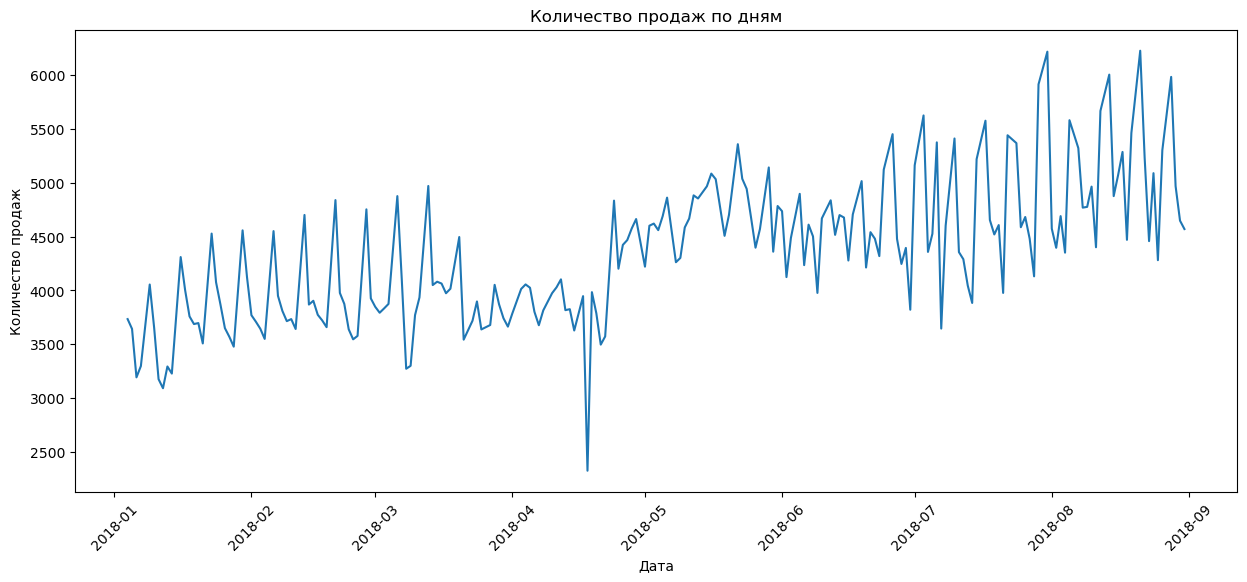

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(
    grouped_df['Дата'],
    grouped_df['Количество продаж']
)

plt.title('Количество продаж по дням')
plt.xlabel('Дата')
plt.ylabel('Количество продаж')
plt.xticks(rotation=45)

plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [ ]:
# На графике показано изменение количества продаж по дням
# за период с января по август 2018 года.
#
# Продажи заметно меняются от дня к дню.
# В начале периода количество продаж в основном находится
# примерно на уровне 3000-4000 единиц в день.
#
# В дальнейшем наблюдается рост продаж.
# Есть дни с заметными пиками, когда количество продаж
# значительно выше среднего уровня.
#
# Также есть отдельные дни со снижением количества продаж.
# Максимальные дневные продажи превышают 6000 единиц.
#
# В целом на графике можно заметить тенденцию к увеличению
# количества продаж к летним месяцам, хотя присутствуют
# значительные ежедневные колебания.

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [13]:
df.loc[df['Количество'].idxmax()]

Дата            2018-06-28 00:00:00
Склад                             1
Контрагент              address_208
Номенклатура              product_0
Количество                      200
Name: 218822, dtype: object

Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [15]:
# Оставляем июнь, июль и август
summer_df = df[df['Дата'].dt.month.isin([6, 7, 8])]

# Оставляем только среды
wednesday_df = summer_df[summer_df['Дата'].dt.dayofweek == 2]

# Оставляем склады 1, 2 и 3
wednesday_df = wednesday_df[wednesday_df['Склад'].isin([1, 2, 3])]

In [16]:
product_sales = (
    wednesday_df
    .groupby(['Склад', 'Номенклатура'])['Количество']
    .sum()
    .reset_index()
)

product_sales.head()

,Склад,Номенклатура,Количество
0,1,product_0,1594
1,1,product_1,2981
2,1,product_10,128
3,1,product_11,62
4,1,product_12,82


In [17]:
top_products = product_sales.loc[
    product_sales.groupby('Склад')['Количество'].idxmax()
]

top_products

,Склад,Номенклатура,Количество
1,1,product_1,2981
24,2,product_1,2887
46,3,product_1,2267


In [ ]:
#На всех трёх складах топовый товар по средам летом — product_1.

Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане (скачайте исходные данные, и далее преобразуйте так, чтобы мы имели Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`, и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. А также отдельно график температуры.

In [23]:
weather = pd.read_csv(
    'weather.csv.gz',
    sep=';',
    compression='gzip',
    comment='#'
)

weather.head()

,Местное время в Астане,T,Po,P,Pa,U,DD,Ff,ff10,ff3,...,Cm,Ch,VV,Td,RRR,tR,E,Tg,E',sss
31.08.2018 23:00,8.2,736.6,768.3,0.2,78.0,"Ветер, дующий с северо-востока",4,NaN,NaN,70 – 80%.,...,"Перистых, перисто-кучевых или перисто-слоистых...",NaN,4.6,Следы осадков,12.0,NaN,NaN,NaN,NaN,NaN
31.08.2018 20:00,9.6,736.4,767.9,1.2,88.0,"Ветер, дующий с западо-северо-запада",3,NaN,NaN,"90 или более, но не 100%",...,"Перистых, перисто-кучевых или перисто-слоистых...",NaN,7.7,Следы осадков,12.0,NaN,NaN,NaN,NaN,NaN
31.08.2018 17:00,11.3,735.2,766.4,0.4,83.0,"Ветер, дующий с востоко-северо-востока",4,NaN,NaN,100%.,...,NaN,10.0,8.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31.08.2018 14:00,12.3,734.8,765.9,0.9,80.0,"Ветер, дующий с северо-востока",4,NaN,NaN,100%.,...,NaN,4.0,8.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
31.08.2018 11:00,13.2,733.9,764.8,1.0,83.0,"Ветер, дующий с северо-северо-востока",4,NaN,NaN,100%.,...,NaN,10.0,10.3,3.0,12.0,NaN,NaN,NaN,NaN,NaN


In [24]:
weather_clean = pd.DataFrame()

weather_clean['Дата'] = pd.to_datetime(
    weather.index,
    format='%d.%m.%Y %H:%M'
)

weather_clean['T'] = weather.iloc[:, 0].values

weather_clean.head()

,Дата,T
0,2018-08-31 23:00:00,8.2
1,2018-08-31 20:00:00,9.6
2,2018-08-31 17:00:00,11.3
3,2018-08-31 14:00:00,12.3
4,2018-08-31 11:00:00,13.2


In [25]:
weather_clean['День'] = weather_clean['Дата'].dt.date

weather_daily = weather_clean.groupby('День')['T'].mean().reset_index()

weather_daily.head()

,День,T
0,2018-01-04,-14.0750
1,2018-01-05,-16.8625
2,2018-01-06,-13.3000
3,2018-01-07,-12.7500
4,2018-01-08,-15.4125


In [26]:
weather_daily['День'] = pd.to_datetime(weather_daily['День'])

weather_daily.dtypes

День    datetime64[ns]
T              float64
dtype: object

In [27]:
weather_daily = weather_daily.rename(
    columns={'День': 'Дата'}
)

weather_daily.head()

,Дата,T
0,2018-01-04,-14.0750
1,2018-01-05,-16.8625
2,2018-01-06,-13.3000
3,2018-01-07,-12.7500
4,2018-01-08,-15.4125


In [28]:
merged_df = pd.merge(
    grouped_df,
    weather_daily,
    on='Дата',
    how='left'
)

merged_df.head()

,Дата,Количество продаж,T
0,2018-01-04,3734,-14.0750
1,2018-01-05,3643,-16.8625
2,2018-01-06,3193,-13.3000
3,2018-01-07,3298,-12.7500
4,2018-01-09,4055,-6.2500


In [29]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Дата               205 non-null    datetime64[ns]
 1   Количество продаж  205 non-null    int64         
 2   T                  205 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 4.9 KB


In [30]:
merged_df.isnull().sum()

Дата                 0
Количество продаж    0
T                    0
dtype: int64

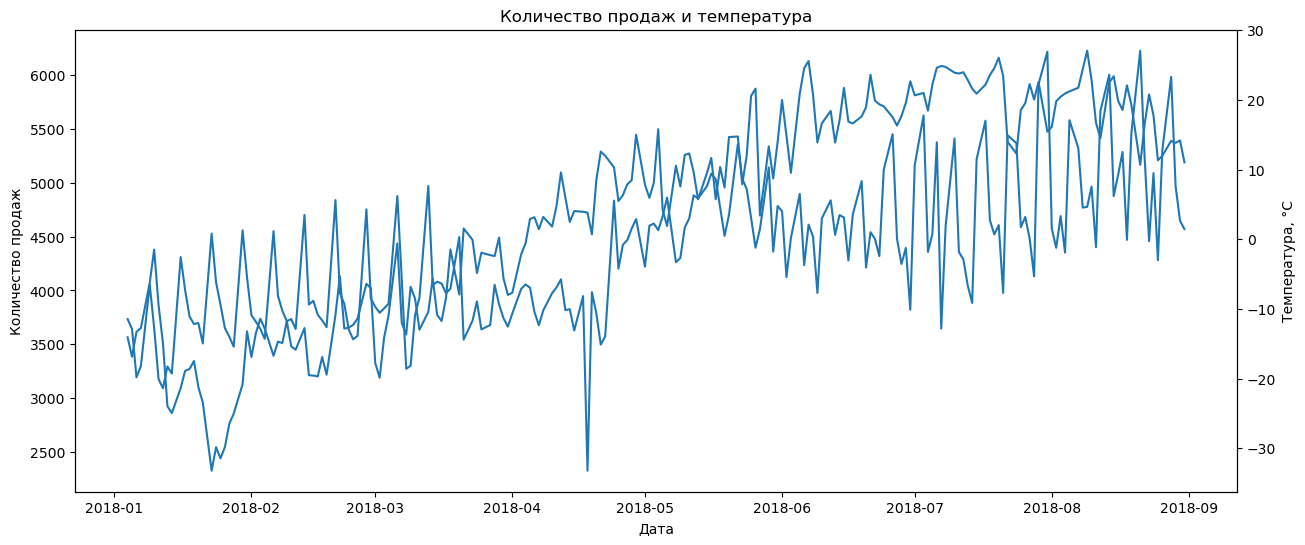

In [31]:
fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    merged_df['Дата'],
    merged_df['Количество продаж']
)

ax1.set_xlabel('Дата')
ax1.set_ylabel('Количество продаж')

ax2 = ax1.twinx()

ax2.plot(
    merged_df['Дата'],
    merged_df['T']
)

ax2.set_ylabel('Температура, °C')

plt.title('Количество продаж и температура')

plt.show()